# Отбор и качество: что остается за пределами оценки

## 1. Вопрос и границы

Модель может оцениваться только на записях с доступными признаками. Как меняется
результат, если одновременно показать метрики внутри этой части и покрытие
всех исходных событий? Проверяем фиксированные прогнозы 08 без обучения.

Протокол: `reports/research_extension_protocol.md`. Анализ запланирован после
просмотра test; его статус **исследовательский**, не новая независимая проверка.
Сценарии требований к метаданным были описаны еще в 04. Сырые значения не меняем.

Исходный знаменатель — опубликованные события с посадкой в январе–мае 2023 UTC.
Это неполный наблюдаемый период, а не все реальные события в Европе.
Оценка C40-модели на записях без C40 неизвестна и здесь не выдумывается.

In [1]:
from pathlib import Path
import os,json,hashlib
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from sklearn.metrics import average_precision_score,roc_auc_score,brier_score_loss
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd().resolve()
while not (ROOT/'reports/baseline_frozen_selection.json').exists():
    if ROOT==ROOT.parent: raise FileNotFoundError('Сначала выполните 08')
    ROOT=ROOT.parent
R=ROOT/'reports';F=ROOT/'figures';LOCAL=ROOT/'data'
DATA_ROOT=Path(os.environ.get('SAMPLE_SELECTION_DATA_ROOT',ROOT.parents[1]))
base=json.loads((R/'verification.json').read_text(encoding='utf-8'))
entries={x['stage']:x for x in base['inputs'] if x['stage'] in ['source','final']}
def resolve(entry):
    p=DATA_ROOT/entry['file'].replace(chr(92),'/')
    if not p.exists():p=LOCAL/Path(entry['file'].replace(chr(92),'/')).name
    return p
def sha(path):
    h=hashlib.sha256()
    with path.open('rb') as stream:
        for b in iter(lambda:stream.read(8*1024*1024),b''):h.update(b)
    return h.hexdigest()
paths={s:resolve(e) for s,e in entries.items()}
for s,p in paths.items(): assert sha(p)==entries[s]['sha256']
PRED=LOCAL/'08_test_predictions.parquet';FREEZE=R/'baseline_frozen_selection.json'
digest_pred=sha(PRED);digest_freeze=sha(FREEZE)
selection=json.loads(FREEZE.read_text(encoding='utf-8'))
expected=json.loads((R/'errors_verification.json').read_text(encoding='utf-8'))
assert digest_pred==expected['prediction_sha256'] and digest_freeze==expected['selection_sha256']
pred=pq.read_table(PRED).to_pandas()
KEY=['flight_id','icao24','airport','landing_time']
FIELDS=['typecode','icaoaircrafttype','market_segment','AC_CLASS']
START=pd.Timestamp('2023-01-01',tz='UTC');END=pd.Timestamp('2023-06-01',tz='UTC')
plt.rcParams.update({'figure.dpi':120,'font.size':11,'axes.spines.top':False,
 'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18})
COLORS={'geometry':'#00897B','geometry_aircraft':'#D65A4A'}
def save(name):
    plt.tight_layout()
    for ext in ['png','svg']:plt.savefig(F/f'{name}.{ext}',bbox_inches='tight')
    plt.show()

## 2. Проверяемое соединение с исходной популяцией

source_row относится к порядку строк final, а не source. Сначала восстанавливаем
точный ключ из final, проверяем GoA, аэропорт и C40. Затем выполняем соединение
с source с проверкой уникальности и без приближенного временного сопоставления.
Посадка задает только знаменатель аудита, не признак модели.

In [2]:
pieces=[];offset=0
for batch in pq.ParquetFile(paths['final']).iter_batches(batch_size=200000,columns=KEY+['GoA','C40_CROSS_TIME']+FIELDS):
    d=batch.to_pandas();d['source_row']=np.arange(offset,offset+len(d));offset+=len(d)
    pieces.append(d[d.landing_time.ge(START)&d.landing_time.lt(END)])
final_period=pd.concat(pieces,ignore_index=True);del pieces
assert offset==entries['final']['rows'] and not final_period.duplicated(KEY).any()
scored=pred.merge(final_period,on='source_row',how='left',validate='one_to_one',suffixes=('_pred',''))
assert scored.landing_time.notna().all()
for f in ['airport','GoA','C40_CROSS_TIME']:assert scored[f].equals(scored[f+'_pred'])
scored=scored.drop(columns=['airport_pred','GoA_pred','C40_CROSS_TIME_pred'])
pieces=[];attempt_checks={'rows':0,'unsorted_lists':0,'first_not_minimum':0}
cols=KEY+['GoA','C40_CROSS_TIME','C40_BEARING','C40_CROSS_LAT','C40_CROSS_LON','attempt_times']
for batch in pq.ParquetFile(paths['source']).iter_batches(batch_size=200000,columns=cols):
    d=batch.to_pandas()
    # Независимая проверка первого элемента против минимального времени во всем источнике.
    a=d.attempt_times
    assert a.map(len).gt(0).all()
    attempt_checks['rows']+=len(d)
    attempt_checks['first_not_minimum']+=int(a.map(lambda x:x[0]!=min(x)).sum())
    attempt_checks['unsorted_lists']+=int(a.map(lambda x:any(x[i]>x[i+1] for i in range(len(x)-1))).sum())
    pieces.append(d[d.landing_time.ge(START)&d.landing_time.lt(END)].drop(columns='attempt_times'))
source=pd.concat(pieces,ignore_index=True);del pieces
assert not source.duplicated(KEY).any()
assert attempt_checks['first_not_minimum']==0
joint=source.merge(scored[KEY+['GoA','geometry','geometry_aircraft']],on=KEY,how='left',
                   validate='one_to_one',suffixes=('','_scored'),indicator=True)
covered=joint['_merge'].eq('both')
assert int(covered.sum())==len(scored)
assert np.array_equal(joint.loc[covered,'GoA'],joint.loc[covered,'GoA_scored'])
assert source.GoA.notna().all() and final_period.GoA.notna().all()
source_total=len(source);source_positive=int(source.GoA.sum())
period=pd.DataFrame([
 {'population':'source_landing_period','rows':source_total,'goa':source_positive},
 {'population':'final_landing_period','rows':len(final_period),'goa':int(final_period.GoA.sum())},
 {'population':'scored_test','rows':len(scored),'goa':int(scored.GoA.sum())}])
period['row_coverage']=period.rows/source_total;period['positive_coverage']=period.goa/source_positive
period.to_csv(R/'selection_evaluation_population.csv',index=False)
display(period);display(attempt_checks)
groups=joint.assign(month=joint.landing_time.dt.strftime('%Y-%m'),scored=covered,
                    scored_goa=covered&joint.GoA).groupby(['airport','month']).agg(
 rows=('GoA','size'),goa=('GoA','sum'),scored_rows=('scored','sum'),scored_goa=('scored_goa','sum')).reset_index()
groups['row_coverage']=groups.scored_rows/groups.rows
groups['positive_coverage']=groups.scored_goa/groups.goa.replace(0,np.nan)
groups.to_csv(R/'selection_evaluation_source_groups.csv',index=False)
assert groups.rows.sum()==source_total and groups.goa.sum()==source_positive
assert groups.scored_rows.sum()==len(scored) and groups.scored_goa.sum()==scored.GoA.sum()

,population,rows,goa,row_coverage,positive_coverage
0,source_landing_period,792225,2810,1.000000,1.000000
1,final_landing_period,546578,1739,0.689928,0.618861
2,scored_test,546577,1739,0.689926,0.618861


{'rows': 7984254, 'unsorted_lists': 0, 'first_not_minimum': 0}

## 3. Метрика внутри покрытия и результат на всей базе

Пусть $G$ — правило допуска записи, $Y$ — исходная метка, $\hat Y$ — фиксированное
пороговое решение. Тогда:

$$P(G=1,\hat Y=1\mid Y=1)=P(G=1\mid Y=1)\,P(\hat Y=1\mid G=1,Y=1).$$

Левая часть — доля найденных положительных событий среди всех событий базы.
Правая — покрытие GoA × recall внутри покрытия. Это проверяемое тождество,
не оценка причинного эффекта. Положительные события вне покрытия отделены от FN.

Дополнительно приводим AP при общей частоте GoA: веса положительного и
отрицательного классов заменяют их пропорции частотой полной test-базы,
сохраняя распределение scores внутри каждого класса. Это только диагностика
эффекта частоты; состав аэропортов и свойства событий она не выравнивает.

In [3]:
def present(f):return scored[f].notna()&scored[f].ne('').fillna(False)
masks={'C40_context':np.ones(len(scored),dtype=bool),
 'raw_typecode':present('typecode').to_numpy(),
 'raw_aircraft_class':(present('typecode')&present('icaoaircrafttype')).to_numpy(),
 'raw_metadata_bundle':np.logical_and.reduce([present(f).to_numpy() for f in FIELDS])}
labels={'C40_context':'Без требований\nк типам','raw_typecode':'Есть typecode',
 'raw_aircraft_class':'Typecode и\nописание','raw_metadata_bundle':'Полные\nметаданные'}
y=scored.GoA.to_numpy(dtype=np.int8);target_prevalence=float(y.mean());results=[]
for scenario,mask in masks.items():
    ys=y[mask];n=len(ys);positive=int(ys.sum())
    for model in COLORS:
        p=scored.loc[mask,model].to_numpy();t=selection['chosen'][model]['threshold'];a=p>=t
        tp=int((a&(ys==1)).sum());fp=int((a&(ys==0)).sum());fn=positive-tp;tn=n-positive-fp
        recall=tp/positive if positive else np.nan
        standardized_ap=np.nan
        if 0<positive<n:
            w=np.where(ys==1,target_prevalence/(positive/n),(1-target_prevalence)/(1-positive/n))
            standardized_ap=float(average_precision_score(ys,p,sample_weight=w))
        results.append({'scenario':scenario,'model':model,'rows':n,'goa':positive,
          'row_coverage_test':n/len(y),'positive_coverage_test':positive/int(y.sum()),
          'prevalence':positive/n if n else np.nan,
          'AP':float(average_precision_score(ys,p)) if positive else np.nan,
          'AP_common_prevalence':standardized_ap,
          'ROC_AUC':float(roc_auc_score(ys,p)) if 0<positive<n else np.nan,
          'Brier':float(brier_score_loss(ys,p)) if n else np.nan,
          'tp':tp,'fp':fp,'fn_in_coverage':fn,'tn':tn,
          'goa_outside_test_coverage':int(y.sum())-positive,'recall_in_coverage':recall,
          'found_fraction_test':tp/int(y.sum()),'positive_coverage_source':positive/source_positive,
          'found_fraction_source':tp/source_positive,'goa_outside_source_coverage':source_positive-positive})
        if positive:
            assert np.isclose((positive/int(y.sum()))*recall,tp/int(y.sum()))
            assert np.isclose((positive/source_positive)*recall,tp/source_positive)
        assert tp+fp+fn+tn==n and positive+(int(y.sum())-positive)==int(y.sum())
result=pd.DataFrame(results);result.to_csv(R/'selection_evaluation_metrics.csv',index=False)
original=pd.read_csv(R/'baseline_metrics.csv').query('split=="test"').set_index('model')
for model in COLORS:
    q=result[result.scenario.eq('C40_context')&result.model.eq(model)].iloc[0]
    for field in ['rows','goa','tp','fp','tn','AP','ROC_AUC','Brier']:
        assert np.isclose(q[field],original.loc[model,field],rtol=1e-10,atol=1e-14)
display(result.style.format(precision=5))

,scenario,model,rows,goa,row_coverage_test,positive_coverage_test,prevalence,AP,AP_common_prevalence,ROC_AUC,Brier,tp,fp,fn_in_coverage,tn,goa_outside_test_coverage,recall_in_coverage,found_fraction_test,positive_coverage_source,found_fraction_source,goa_outside_source_coverage
0,C40_context,geometry,546577,1739,1.00000,1.00000,0.00318,0.00376,0.00376,0.56234,0.00317,768,187348,971,357490,0,0.44163,0.44163,0.61886,0.27331,1071
1,C40_context,geometry_aircraft,546577,1739,1.00000,1.00000,0.00318,0.00398,0.00398,0.57230,0.00317,35,9500,1704,535338,0,0.02013,0.02013,0.61886,0.01246,1071
2,raw_typecode,geometry,523280,1655,0.95738,0.95170,0.00316,0.00373,0.00375,0.56021,0.00315,716,177283,939,344342,84,0.43263,0.41173,0.58897,0.25480,1155
3,raw_typecode,geometry_aircraft,523280,1655,0.95738,0.95170,0.00316,0.00395,0.00397,0.57074,0.00315,35,9468,1620,512157,84,0.02115,0.02013,0.58897,0.01246,1155
4,raw_aircraft_class,geometry,516253,1629,0.94452,0.93675,0.00316,0.00372,0.00375,0.56095,0.00315,705,174328,924,340296,110,0.43278,0.40541,0.57972,0.25089,1181
5,raw_aircraft_class,geometry_aircraft,516253,1629,0.94452,0.93675,0.00316,0.00399,0.00402,0.57200,0.00314,26,6286,1603,508338,110,0.01596,0.01495,0.57972,0.00925,1181
6,raw_metadata_bundle,geometry,92,0,0.00017,0.00000,0.00000,nan,nan,nan,0.00001,0,46,0,46,1739,nan,0.00000,0.00000,0.00000,2810
7,raw_metadata_bundle,geometry_aircraft,92,0,0.00017,0.00000,0.00000,nan,nan,nan,0.00001,0,6,0,86,1739,nan,0.00000,0.00000,0.00000,2810


## 4. Рисунки с явными знаменателями

Ноль найденных событий не означает нулевого риска. Полный набор метаданных
может оставить настолько мало GoA, что AP не определена. Это результат
проверки покрытия, а не основание скрывать сценарий из таблицы.

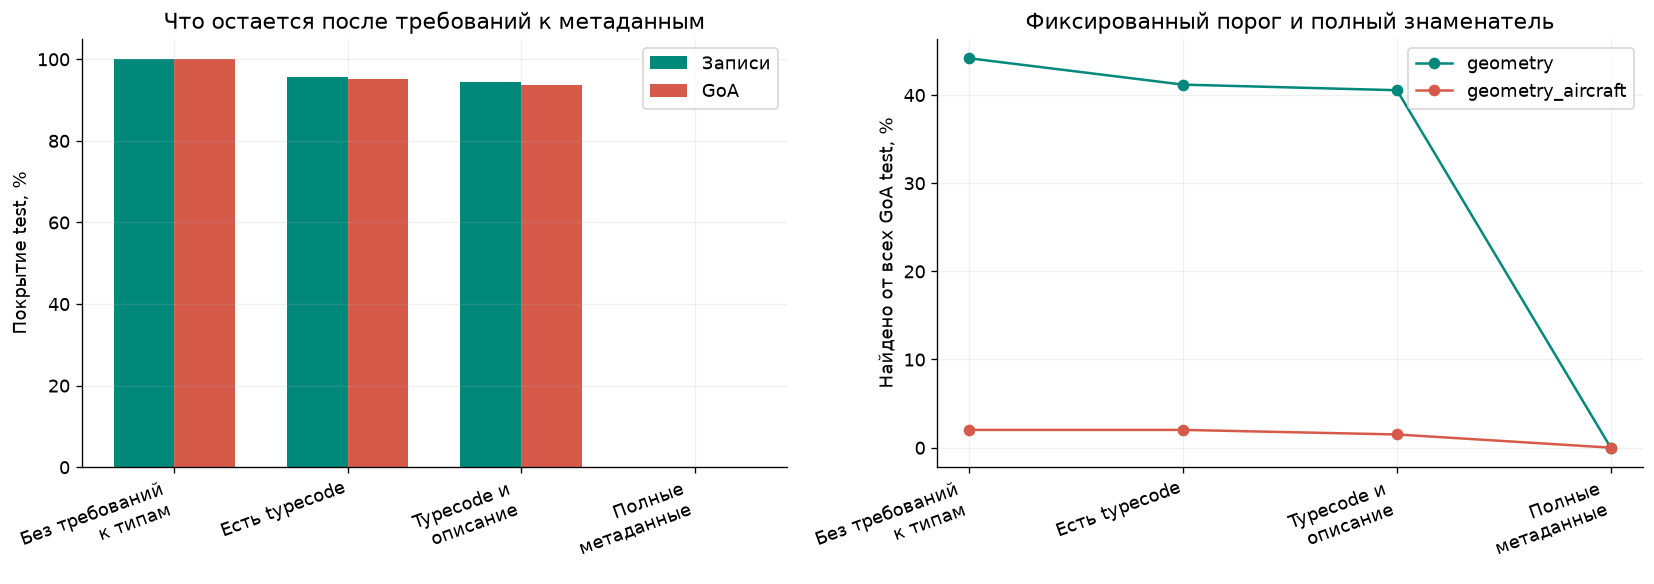

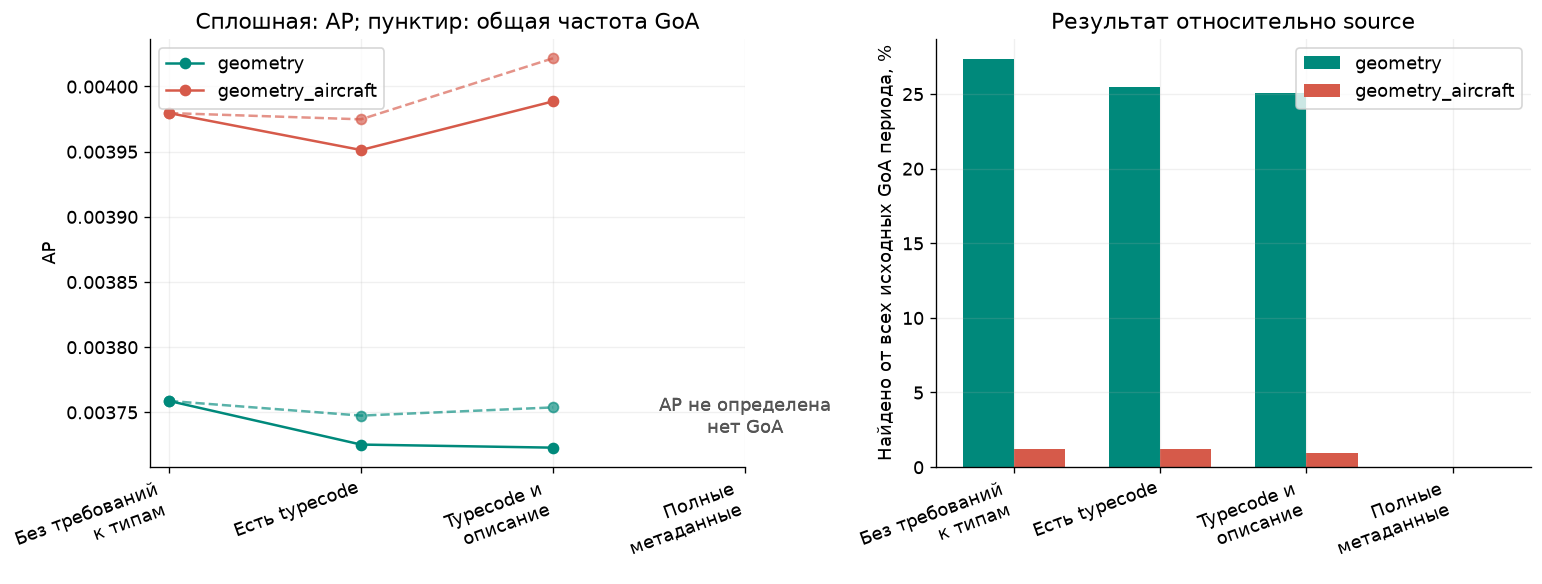

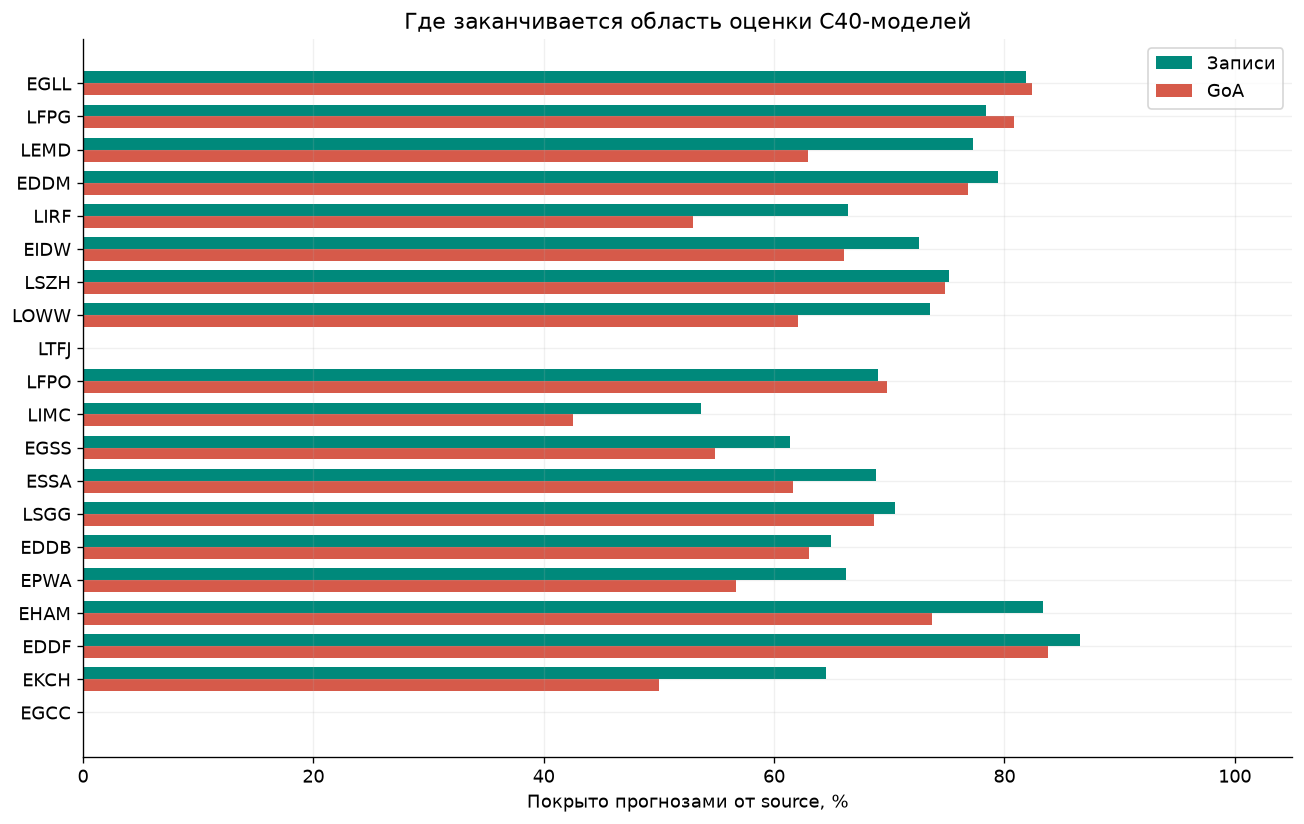

In [4]:
q=result[result.model.eq('geometry')].set_index('scenario').reindex(masks)
x=np.arange(len(q));width=.35
fig,axes=plt.subplots(1,2,figsize=(14,5))
axes[0].bar(x-width/2,100*q.row_coverage_test,width,color='#00897B',label='Записи')
axes[0].bar(x+width/2,100*q.positive_coverage_test,width,color='#D65A4A',label='GoA')
axes[0].set(ylabel='Покрытие test, %',title='Что остается после требований к метаданным',ylim=(0,105));axes[0].legend()
for model,color in COLORS.items():
    a=result[result.model.eq(model)].set_index('scenario').reindex(masks)
    axes[1].plot(x,100*a.found_fraction_test,'o-',color=color,label=model)
axes[1].set(ylabel='Найдено от всех GoA test, %',title='Фиксированный порог и полный знаменатель');axes[1].legend()
for ax in axes:ax.set_xticks(x,[labels[s] for s in masks],rotation=20,ha='right')
save('32_selection_quality_coverage')
fig,axes=plt.subplots(1,2,figsize=(13,5))
for model,color in COLORS.items():
    a=result[result.model.eq(model)].set_index('scenario').reindex(masks)
    axes[0].plot(x,a.AP,'o-',color=color,label=model)
    axes[0].plot(x,a.AP_common_prevalence,'o--',color=color,alpha=.65)
    for i,row in enumerate(a.itertuples()):
        if row.goa==0:axes[0].text(i,.08,'AP не определена\nнет GoA',ha='center',transform=axes[0].get_xaxis_transform(),color='#555555')
    axes[1].bar(x+(-width/2 if model=='geometry' else width/2),
                 100*a.found_fraction_source,width,color=color,label=model)
axes[0].set(ylabel='AP',title='Сплошная: AP; пунктир: общая частота GoA');axes[0].legend()
axes[1].set(ylabel='Найдено от всех исходных GoA периода, %',title='Результат относительно source');axes[1].legend()
for ax in axes:ax.set_xticks(x,[labels[s] for s in masks],rotation=20,ha='right')
save('33_selection_metric_denominators')
a=groups.groupby('airport')[['rows','goa','scored_rows','scored_goa']].sum()
a=a.sort_values('rows',ascending=False)
fig,ax=plt.subplots(figsize=(11,7));z=np.arange(len(a))
ax.barh(z-.18,100*a.scored_rows/a.rows,.36,color='#00897B',label='Записи')
ax.barh(z+.18,100*a.scored_goa/a.goa,.36,color='#D65A4A',label='GoA')
ax.set_yticks(z,a.index);ax.invert_yaxis();ax.set(xlabel='Покрыто прогнозами от source, %',xlim=(0,105),
 title='Где заканчивается область оценки C40-моделей');ax.legend()
save('34_source_scoring_coverage')

## 5. Проверки и вывод

Публичные результаты содержат агрегаты; соединенные идентификаторы не экспортируются.
Вне покрытия C40-модели качество неизвестно. Более высокая условная AP после
отбора не доказывает улучшение модели на всей исходной популяции.

In [5]:
for s,p in paths.items():assert sha(p)==entries[s]['sha256']
assert sha(PRED)==digest_pred and sha(FREEZE)==digest_freeze
verification={'source_sha256':entries['source']['sha256'],'final_sha256':entries['final']['sha256'],
 'prediction_sha256':digest_pred,'selection_sha256':digest_freeze,
 'period_start':str(START),'period_end_exclusive':str(END),'status':'exploratory_after_test_inspection',
 'source_rows':source_total,'source_goa':source_positive,'scored_rows':len(scored),'scored_goa':int(y.sum()),
 'exact_join_passed':True,'group_balances_passed':True,'coverage_identity_passed':True,
 'baseline_metrics_match':True,'attempt_order_audit':attempt_checks,
 'inputs_unchanged':True,'predictions_unchanged':True,'thresholds_unchanged':True,
 'retraining_performed':False,'source_model_AP_identified':False}
(R/'selection_evaluation_verification.json').write_text(json.dumps(verification,indent=2),encoding='utf-8')
text=f"""# Отбор и знаменатель оценки

Исходный наблюдаемый период: {source_total:,} записей / {source_positive:,} GoA.
Фиксированные прогнозы: {len(scored):,} записей / {int(y.sum()):,} GoA.
Покрытие GoA относительно source: {100*int(y.sum())/source_positive:.2f}%.

{result[['scenario','model','rows','goa','AP','recall_in_coverage','found_fraction_test','found_fraction_source']].to_string(index=False)}

Измерена зависимость отчетного результата от знаменателя и требования полноты.
Положительные события вне покрытия выделены отдельно от FN модели.
AP C40-моделей для всей source не идентифицирована: отсутствуют их scores вне покрытия.
Метрики не превращаются в оценку всех реальных посадок или эксплуатационного эффекта.
Анализ исследовательский после просмотра test. Данные, модели и пороги неизменны.
"""
(R/'selection_evaluation_findings.md').write_text(text,encoding='utf-8');display(Markdown(text))

# Отбор и знаменатель оценки

Исходный наблюдаемый период: 792,225 записей / 2,810 GoA.
Фиксированные прогнозы: 546,577 записей / 1,739 GoA.
Покрытие GoA относительно source: 61.89%.

           scenario             model   rows  goa       AP  recall_in_coverage  found_fraction_test  found_fraction_source
        C40_context          geometry 546577 1739 0.003759            0.441633             0.441633               0.273310
        C40_context geometry_aircraft 546577 1739 0.003980            0.020127             0.020127               0.012456
       raw_typecode          geometry 523280 1655 0.003725            0.432628             0.411731               0.254804
       raw_typecode geometry_aircraft 523280 1655 0.003951            0.021148             0.020127               0.012456
 raw_aircraft_class          geometry 516253 1629 0.003723            0.432781             0.405405               0.250890
 raw_aircraft_class geometry_aircraft 516253 1629 0.003989            0.015961             0.014951               0.009253
raw_metadata_bundle          geometry     92    0      NaN                 NaN             0.000000               0.000000
raw_metadata_bundle geometry_aircraft     92    0      NaN                 NaN             0.000000               0.000000

Измерена зависимость отчетного результата от знаменателя и требования полноты.
Положительные события вне покрытия выделены отдельно от FN модели.
AP C40-моделей для всей source не идентифицирована: отсутствуют их scores вне покрытия.
Метрики не превращаются в оценку всех реальных посадок или эксплуатационного эффекта.
Анализ исследовательский после просмотра test. Данные, модели и пороги неизменны.
